# **TASK 02**

In [1]:
# Setup: portable paths (works in Colab from the cloned repo, or locally)
import os, json, warnings
warnings.filterwarnings("ignore")

if not os.path.exists("data/common_share_set.csv"):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        os.chdir('/content/drive/MyDrive/CRM_Coursework')
    except ImportError:
        pass
assert os.path.exists("data/common_share_set.csv"), "Run Task 1 first or clone the repository"

Mounted at /content/drive


In [2]:
# Imports, parameters and package versions
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import scipy, sklearn
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

SEED   = 42
N_INIT = 50
K_RANGE = range(2, 9)
os.makedirs("outputs/figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

pandas 2.2.3 | numpy 2.4.6 | scipy 1.16.3 | scikit-learn 1.6.1 | matplotlib 3.10.0 | seaborn 0.13.2


## Task 2.1


In [3]:
# Load the common valid share set and build the two separate feature matrices
df = pd.read_csv("data/common_share_set.csv", index_col=0)
core = ["mean_weekly_return", "weekly_beta", "R", "F", "M"]
assert df[core].notna().all().all() and df.index.is_unique
df["logM"] = np.log1p(df["M"])
df["M_bn"] = df["M"] / 1e9

RR_COLS  = ["mean_weekly_return", "weekly_beta"]
ACT_COLS = ["R", "F", "logM"]
print("Common share set:", df.shape[0], "shares (same shares used in every clustering solution)")

Common share set: 485 shares (same shares used in every clustering solution)


In [4]:
# Skew and outlier diagnostics (raw vs transformed) on the clustering inputs
diag = pd.DataFrame({
    "skew_raw":  df[["mean_weekly_return", "weekly_beta", "R", "F", "M"]].skew(),
}).round(2)
diag["skew_after_log1p"] = pd.Series({
    "mean_weekly_return": np.nan, "weekly_beta": np.nan,
    "R": np.log1p(df["R"]).skew(), "F": np.log1p(df["F"]).skew(), "M": df["logM"].skew()}).round(2)

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())
diag["IQR_outliers"] = pd.Series({c: iqr_outliers(df[c]) for c in ["mean_weekly_return", "weekly_beta", "R", "F", "logM"]})
diag.loc["M", "IQR_outliers"] = iqr_outliers(df["M"])
print(diag)
print()
print("Share of shares with R == 11 (same latest high volume day):", round((df["R"] == 11).mean(), 3))

                    skew_raw  skew_after_log1p  IQR_outliers
mean_weekly_return      0.88               NaN          15.0
weekly_beta             1.11               NaN          10.0
R                       3.64              1.59         118.0
F                       0.43             -0.93           2.0
M                      11.67              1.08          45.0

Share of shares with R == 11 (same latest high volume day): 0.728


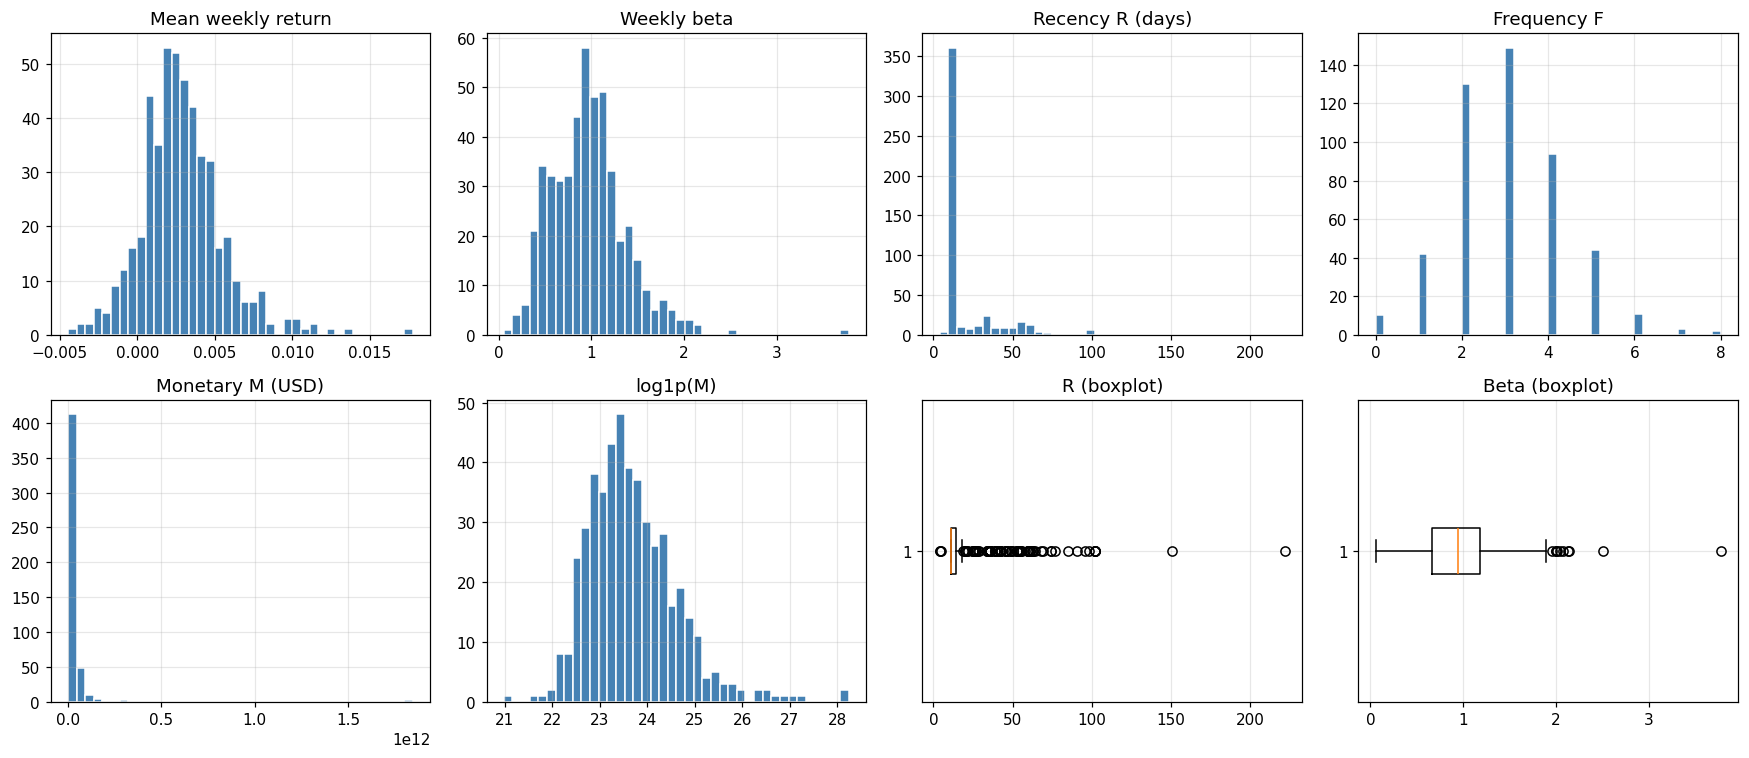

In [5]:
# Distribution plots (raw vs transformed)
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, (c, t) in zip(ax.ravel(), [("mean_weekly_return", "Mean weekly return"), ("weekly_beta", "Weekly beta"),
                                   ("R", "Recency R (days)"), ("F", "Frequency F"),
                                   ("M", "Monetary M (USD)"), ("logM", "log1p(M)"),
                                   ("R", "R (boxplot)"), ("weekly_beta", "Beta (boxplot)")]):
    if "boxplot" in t: a.boxplot(df[c], vert=False)
    else: a.hist(df[c], bins=40, color="steelblue", edgecolor="white")
    a.set_title(t)
plt.tight_layout(); plt.savefig("outputs/figures/2_1_distributions.png"); plt.show()

In [38]:
# Standardise each matrix separately (z-scores), keep scalers so profiles can be shown in original units
sc_rr,  sc_act  = StandardScaler(), StandardScaler()
Z_rr  = sc_rr.fit_transform(df[RR_COLS])
Z_act = sc_act.fit_transform(df[ACT_COLS])
MATS = {"RR": Z_rr, "ACT": Z_act}
print("RR  z-mean:", Z_rr.mean(0).round(6),  "z-std:", Z_rr.std(0).round(3))
print("ACT z-mean:", Z_act.mean(0).round(6), "z-std:", Z_act.std(0).round(3))

RR  z-mean: [0. 0.] z-std: [1. 1.]
ACT z-mean: [ 0. -0. -0.] z-std: [1. 1. 1.]


In [7]:
def relabel(labels, key):
    # Renumber clusters 0..k-1 by ascending median of `key` (readability only; does not change the partition)
    s = pd.Series(labels, index=key.index)
    order = key.groupby(s).median().sort_values().index
    return s.map({old: new for new, old in enumerate(order)}).to_numpy()

def wss(Z, lab):
    return float(sum(((Z[lab == c] - Z[lab == c].mean(0))**2).sum() for c in np.unique(lab)))

In [8]:
# Helper: cluster-count diagnostics table
def diag_table(Z, algo):
    rows = []
    for k in K_RANGE:
        if algo == "ward":
            lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)   # Ward uses Euclidean distance
        else:
            lab = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(Z).labels_
        sizes = np.sort(np.bincount(lab))[::-1]
        rows.append({"k": k, "silhouette": round(silhouette_score(Z, lab), 3), "wss": round(wss(Z, lab), 1),
                     "min_size": int(sizes.min()), "max_size": int(sizes.max()), "sizes": sizes.tolist()})
    return pd.DataFrame(rows).set_index("k")

In [9]:
# Helper: cluster profile in original units
def profile(labels, cols=("mean_weekly_return", "weekly_beta", "R", "F", "M_bn")):
    # Cluster profile in ORIGINAL units (medians; M in USD billions); return in % per week
    g = df[list(cols)].groupby(labels)
    out = g.median()
    out.insert(0, "n_shares", g.size())
    if "mean_weekly_return" in out: out["mean_weekly_return"] *= 100
    return out.rename(columns={"mean_weekly_return": "median_wk_return_%", "weekly_beta": "median_beta",
                               "R": "median_R_days", "F": "median_F", "M_bn": "median_M_USDbn"}).round(3)

In [10]:
# Helper: variance explained and algorithm agreement
def eta_sq(v, lab):
    # share of a variable's variance explained by the clusters (between SS / total SS)
    v = np.asarray(v, float); tss = ((v - v.mean())**2).sum()
    bss = sum((lab == c).sum() * (v[lab == c].mean() - v.mean())**2 for c in np.unique(lab))
    return bss / tss

def matched_agreement(a, b):
    ct = pd.crosstab(a, b).to_numpy(); r, c = linear_sum_assignment(-ct)
    return ct[r, c].sum() / ct.sum()

## Task 2.2


In [11]:
# Compare k = 2..8: silhouette, within-cluster sum of squares, cluster sizes
ward_diag = {name: diag_table(Z, "ward") for name, Z in MATS.items()}
for name, t in ward_diag.items():
    print(f"=== Ward | {name} matrix ==="); print(t); print()
    t.to_csv(f"outputs/diagnostics_ward_{name}.csv")

=== Ward | RR matrix ===
   silhouette    wss  min_size  max_size                             sizes
k                                                                         
2       0.341  702.5        92       393                         [393, 92]
3       0.274  527.3        92       229                    [229, 164, 92]
4       0.282  427.8        47       182                [182, 164, 92, 47]
5       0.304  347.1        47       182             [182, 98, 92, 66, 47]
6       0.321  279.3         5       182          [182, 98, 87, 66, 47, 5]
7       0.325  244.3         5       160      [160, 98, 87, 66, 47, 22, 5]
8       0.323  209.6         5       160  [160, 98, 66, 56, 47, 31, 22, 5]

=== Ward | ACT matrix ===
   silhouette     wss  min_size  max_size                              sizes
k                                                                           
2       0.368  1098.9        82       403                          [403, 82]
3       0.304   835.5        82       249 

In [12]:
# Dendrograms (one per matrix; truncated to the last 30 merges for legibility)
LINK = {name: linkage(Z, method="ward", metric="euclidean") for name, Z in MATS.items()}

def cut_height(Zl, k):
    # a horizontal cut giving exactly k clusters lies between the (k-1)th and kth highest merge heights
    return (Zl[-k, 2] + Zl[-(k-1), 2]) / 2

In [39]:
# CHOSEN CLUSTER COUNTS (edit here after reading the tables above)
K = {"RR": 5, "ACT": 3}

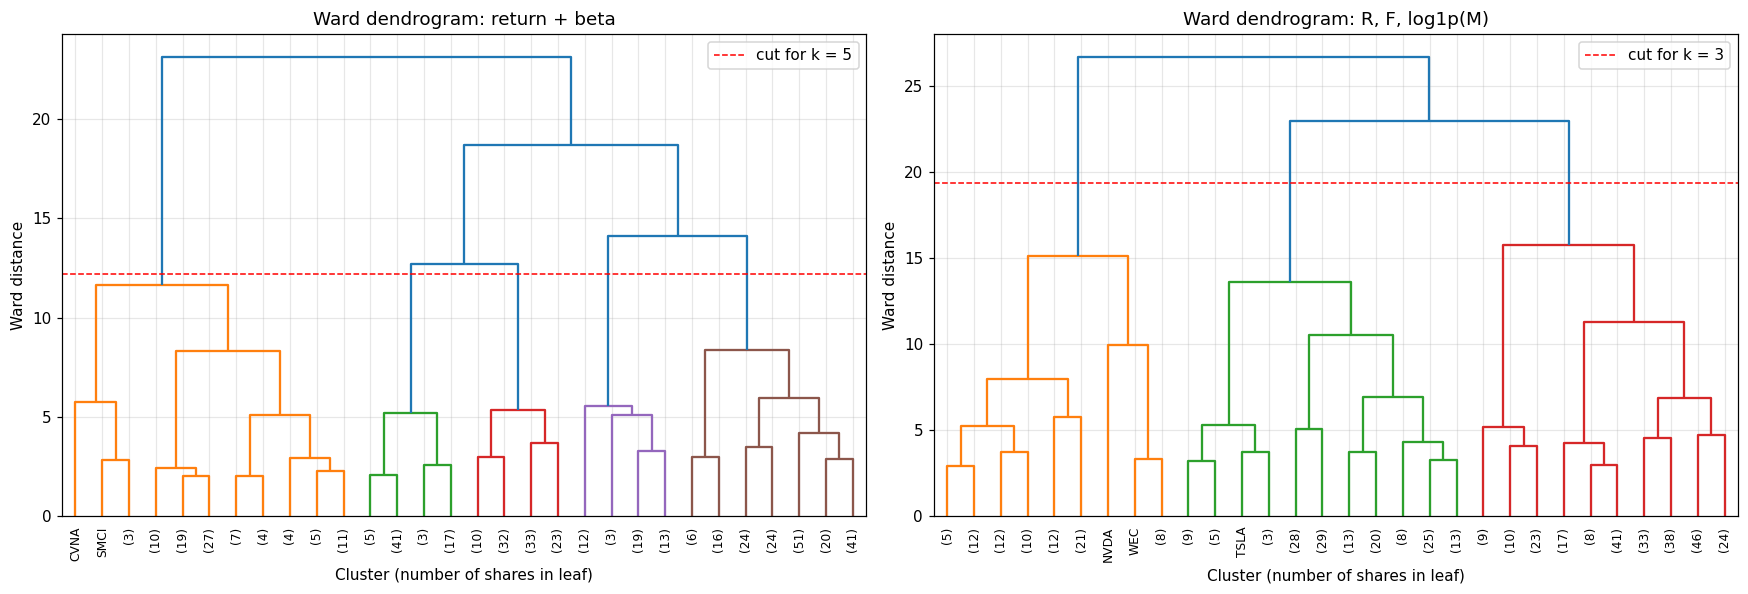

In [15]:
# Draw the two dendrograms with the cut line for the chosen k
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
titles = {"RR": "Ward dendrogram: return + beta", "ACT": "Ward dendrogram: R, F, log1p(M)"}
for a, name in zip(ax, ["RR", "ACT"]):
    h = cut_height(LINK[name], K[name])
    dendrogram(LINK[name], truncate_mode="lastp", p=30, ax=a, labels=df.index.to_numpy(), color_threshold=h,
               leaf_rotation=90, leaf_font_size=8, show_leaf_counts=True)
    a.axhline(h, color="red", ls="--", lw=1, label=f"cut for k = {K[name]}")
    a.set_title(titles[name]); a.set_xlabel("Cluster (number of shares in leaf)"); a.set_ylabel("Ward distance"); a.legend()
plt.tight_layout(); plt.savefig("outputs/figures/2_2_dendrograms.png"); plt.show()

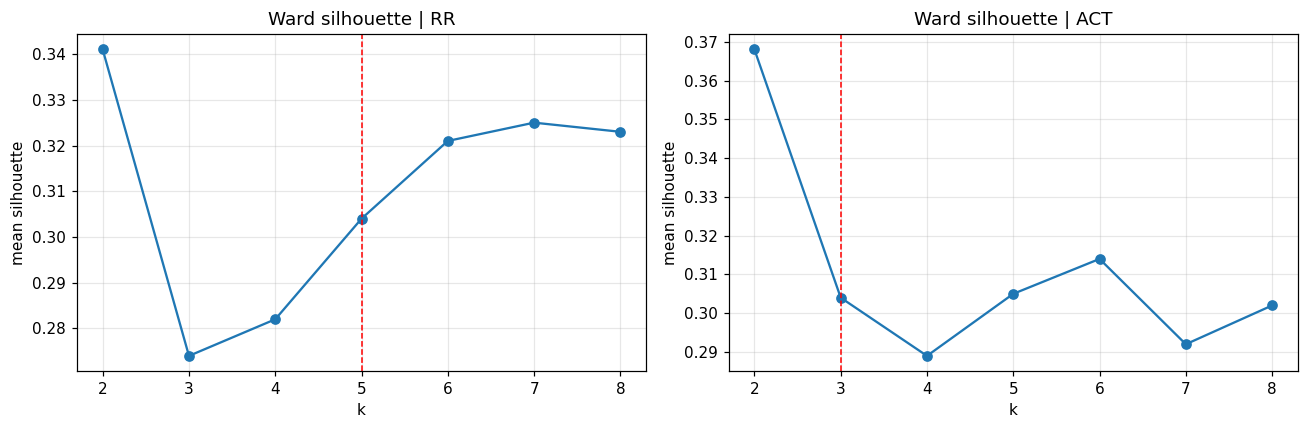

In [16]:
# Silhouette by k for Ward (cluster-count evidence)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, name in zip(ax, ["RR", "ACT"]):
    t = ward_diag[name]; a.plot(t.index, t["silhouette"], "o-")
    a.axvline(K[name], color="red", ls="--", lw=1); a.set_title(f"Ward silhouette | {name}")
    a.set_xlabel("k"); a.set_ylabel("mean silhouette")
plt.tight_layout(); plt.savefig("outputs/figures/2_2_ward_silhouette.png"); plt.show()

In [17]:
# Final Ward labels at the chosen k
ward_labels = {}
ward_labels["RR"]  = relabel(AgglomerativeClustering(n_clusters=K["RR"],  linkage="ward").fit_predict(Z_rr),  df["weekly_beta"])
ward_labels["ACT"] = relabel(AgglomerativeClustering(n_clusters=K["ACT"], linkage="ward").fit_predict(Z_act), df["M"])

##Task 2.3


In [18]:
# Compare k = 2..8 with a fixed seed and multiple initialisations (n_init = 50)
km_diag = {name: diag_table(Z, "kmeans") for name, Z in MATS.items()}
for name, t in km_diag.items():
    print(f"=== K-means | {name} matrix (inertia = wss) ==="); print(t); print()
    t.to_csv(f"outputs/diagnostics_kmeans_{name}.csv")

=== K-means | RR matrix (inertia = wss) ===
   silhouette    wss  min_size  max_size                             sizes
k                                                                         
2       0.389  617.0       143       342                        [342, 143]
3       0.328  459.8       120       202                   [202, 163, 120]
4       0.327  370.2        40       160               [160, 154, 131, 40]
5       0.340  308.1        27       166           [166, 131, 111, 50, 27]
6       0.336  263.4         5       155        [155, 127, 106, 51, 41, 5]
7       0.330  225.3         5       128     [128, 103, 84, 77, 47, 41, 5]
8       0.361  192.7         5       139  [139, 76, 75, 74, 47, 40, 29, 5]

=== K-means | ACT matrix (inertia = wss) ===
   silhouette     wss  min_size  max_size                              sizes
k                                                                           
2       0.423  1064.4        68       417                          [417, 68]
3   

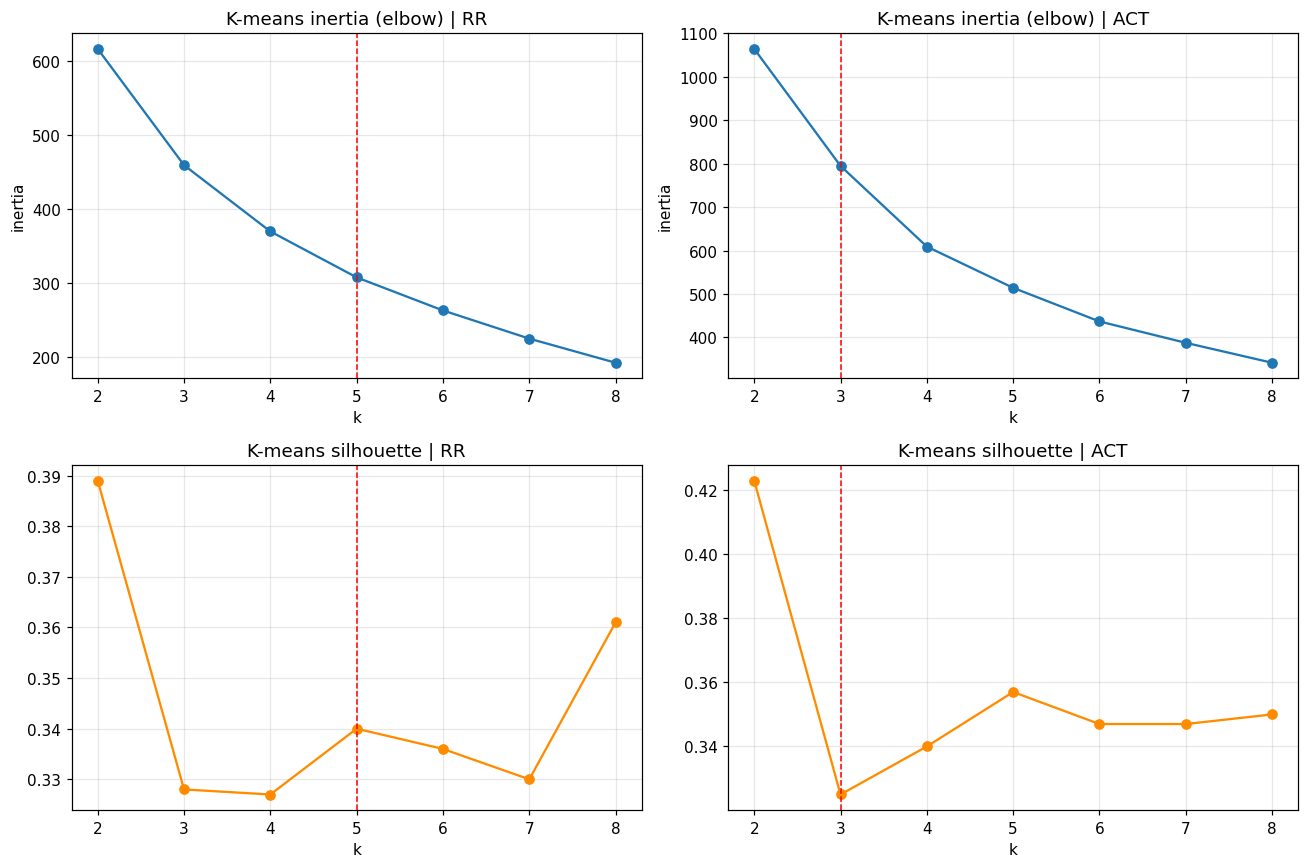

In [19]:
# K-means elbow and silhouette plots
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for j, name in enumerate(["RR", "ACT"]):
    t = km_diag[name]
    ax[0, j].plot(t.index, t["wss"], "o-"); ax[0, j].set_title(f"K-means inertia (elbow) | {name}"); ax[0, j].set_ylabel("inertia")
    ax[1, j].plot(t.index, t["silhouette"], "o-", color="darkorange"); ax[1, j].set_title(f"K-means silhouette | {name}")
    for r in (0, 1): ax[r, j].axvline(K[name], color="red", ls="--", lw=1); ax[r, j].set_xlabel("k")
plt.tight_layout(); plt.savefig("outputs/figures/2_3_kmeans_diagnostics.png"); plt.show()


In [20]:
# Initialisation stability at the chosen k: single random starts vs the multi-start solution
for name, Z in MATS.items():
    ref = KMeans(n_clusters=K[name], n_init=N_INIT, random_state=SEED).fit(Z)
    single = [KMeans(n_clusters=K[name], init="random", n_init=1, random_state=s).fit(Z) for s in range(30)]
    ari = [adjusted_rand_score(ref.labels_, m.labels_) for m in single]
    inert = [m.inertia_ for m in single]
    print(f"{name} k={K[name]} | multi-start inertia {ref.inertia_:.1f} | 30 single random starts: "
          f"inertia range {min(inert):.1f}-{max(inert):.1f}, ARI vs multi-start: mean {np.mean(ari):.3f}, min {np.min(ari):.3f}")

RR k=5 | multi-start inertia 308.2 | 30 single random starts: inertia range 308.5-334.5, ARI vs multi-start: mean 0.587, min 0.297
ACT k=3 | multi-start inertia 794.9 | 30 single random starts: inertia range 794.9-958.4, ARI vs multi-start: mean 0.521, min 0.210


In [21]:
# Final K-means labels at the chosen k
km_labels = {}
km_labels["RR"]  = relabel(KMeans(n_clusters=K["RR"],  n_init=N_INIT, random_state=SEED).fit_predict(Z_rr),  df["weekly_beta"])
km_labels["ACT"] = relabel(KMeans(n_clusters=K["ACT"], n_init=N_INIT, random_state=SEED).fit_predict(Z_act), df["M"])

## Task 2.4

In [22]:
# Profiles in original units: Ward solutions (both matrices)
profiles = {}
def show_profiles(algo, labs):
    for name, cols in [("RR", ("mean_weekly_return", "weekly_beta", "R", "F", "M_bn")),
                       ("ACT", ("R", "F", "M_bn", "mean_weekly_return", "weekly_beta"))]:
        p = profile(labs[name], cols); profiles[(algo, name)] = p
        print(f"=== {algo} | {name} solution (k={K[name]}) — medians in original units ==="); print(p.to_string()); print()
        p.to_csv(f"outputs/profile_{algo}_{name}.csv")

show_profiles("Ward", ward_labels)

=== Ward | RR solution (k=5) — medians in original units ===
   n_shares  median_wk_return_%  median_beta  median_R_days  median_F  median_M_USDbn
0        66               0.113        0.449           11.0       3.0          17.701
1        98               0.392        0.666           11.0       3.0          17.649
2       182               0.166        0.964           11.0       3.0          12.985
3        92               0.550        1.218           11.0       3.0          24.184
4        47               0.253        1.509           11.0       3.0          28.918

=== Ward | ACT solution (k=3) — medians in original units ===
   n_shares  median_R_days  median_F  median_M_USDbn  median_wk_return_%  median_beta
0       249           11.0       3.0          11.154               0.250        0.927
1        82           54.5       2.0          17.849               0.244        1.047
2       154           11.0       3.0          39.695               0.325        0.989



In [23]:
# Profiles in original units: K-means solutions (both matrices)
show_profiles("KMeans", km_labels)

=== KMeans | RR solution (k=5) — medians in original units ===
   n_shares  median_wk_return_%  median_beta  median_R_days  median_F  median_M_USDbn
0       131               0.195        0.534           11.0       3.0          15.044
1       166               0.419        0.985           11.0       3.0          18.112
2       111               0.080        1.039           11.0       3.0          13.079
3        27               0.831        1.450           11.0       3.0          28.211
4        50               0.270        1.525           11.0       3.0          32.859

=== KMeans | ACT solution (k=3) — medians in original units ===
   n_shares  median_R_days  median_F  median_M_USDbn  median_wk_return_%  median_beta
0       269           11.0       3.0          11.336               0.245        0.927
1        64           55.0       2.0          21.147               0.254        1.035
2       152           11.0       3.0          41.602               0.326        0.996



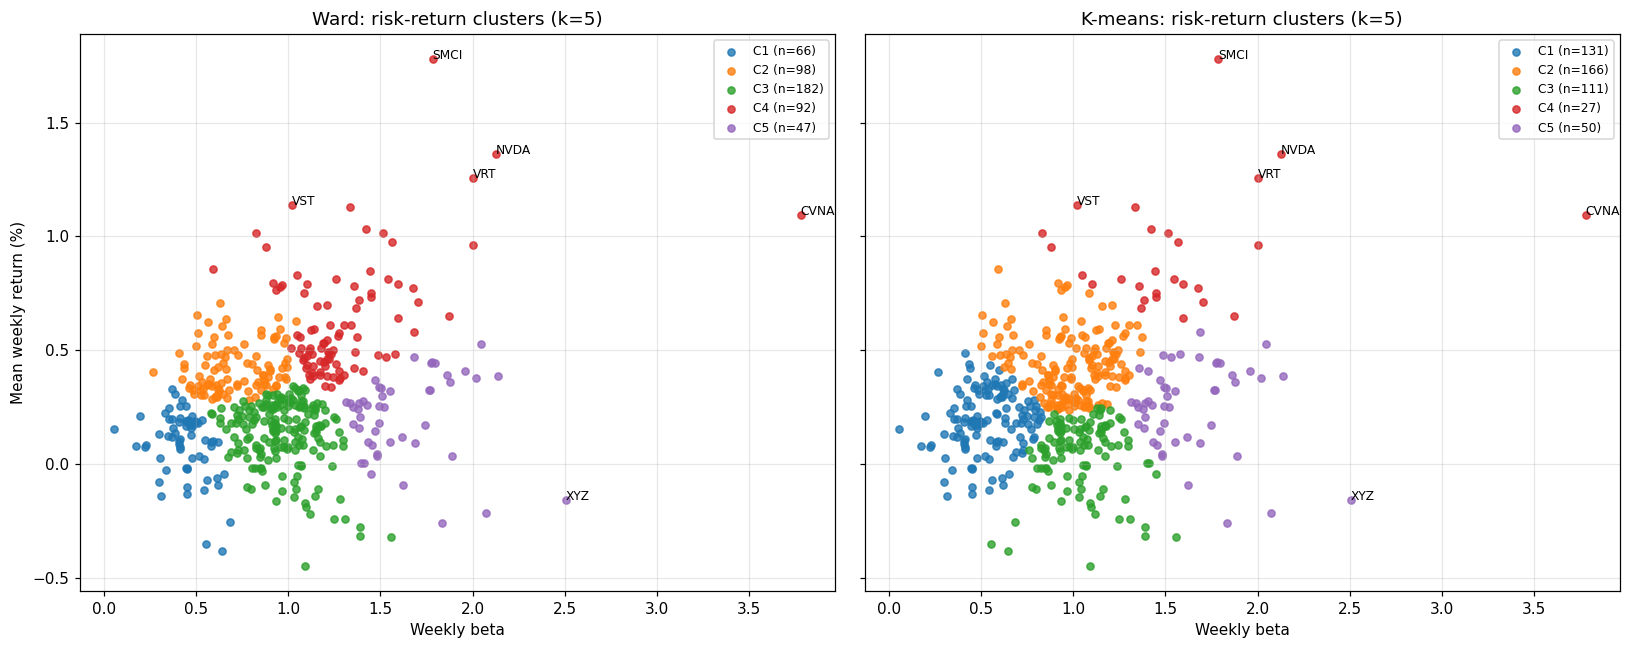

In [24]:
# Visualisation 1: risk-return matrix is already 2-D, so it is plotted directly in original units (no dimensionality reduction)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
pal = sns.color_palette("tab10", 10)
far = np.abs(Z_rr).max(1) > 3.2
for a, (algo, labs) in zip(ax, [("Ward", ward_labels), ("K-means", km_labels)]):
    for c in range(K["RR"]):
        m = labs["RR"] == c
        a.scatter(df.loc[m, "weekly_beta"], df.loc[m, "mean_weekly_return"]*100, s=22, color=pal[c], alpha=.8, label=f"C{c+1} (n={m.sum()})")
    for t in df.index[far]:
        a.annotate(t, (df.loc[t, "weekly_beta"], df.loc[t, "mean_weekly_return"]*100), fontsize=8)
    a.set_title(f"{algo}: risk-return clusters (k={K['RR']})"); a.set_xlabel("Weekly beta"); a.legend(fontsize=8)
ax[0].set_ylabel("Mean weekly return (%)")
plt.tight_layout(); plt.savefig("outputs/figures/2_4_rr_scatter.png"); plt.show()

In [25]:
# Visualisation 2: activity matrix has 3 standardised features, so PCA projects it to 2-D for plotting ONLY (clustering used all 3)
# (the diagonal stripes appear because R and F are whole numbers)
pca = PCA(n_components=2, random_state=SEED).fit(Z_act)
P = pca.transform(Z_act)
print("PCA explained variance ratio:", pca.explained_variance_ratio_.round(3), "| total", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_.T, index=["R", "F", "log1p(M)"], columns=["PC1", "PC2"]).round(2))

PCA explained variance ratio: [0.458 0.337] | total 0.795
           PC1   PC2
R         0.71  0.02
F        -0.65  0.40
log1p(M)  0.27  0.92


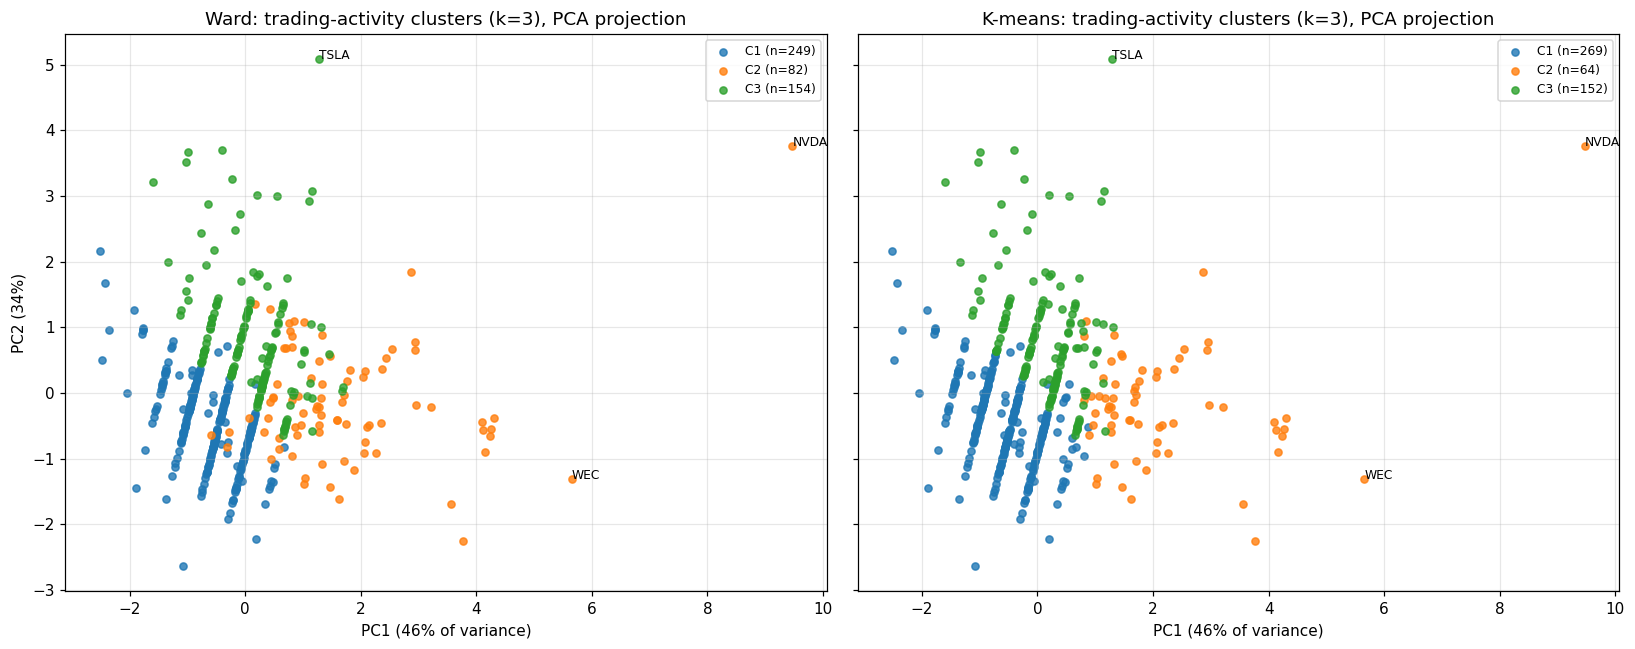

In [26]:
# Plot the PCA projection coloured by cluster
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
far = np.abs(Z_act).max(1) > 4.0
for a, (algo, labs) in zip(ax, [("Ward", ward_labels), ("K-means", km_labels)]):
    for c in range(K["ACT"]):
        m = labs["ACT"] == c
        a.scatter(P[m, 0], P[m, 1], s=22, color=pal[c], alpha=.8, label=f"C{c+1} (n={m.sum()})")
    for t, (x, y) in zip(df.index[far], P[far]): a.annotate(t, (x, y), fontsize=8)
    a.set_title(f"{algo}: trading-activity clusters (k={K['ACT']}), PCA projection")
    a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)"); a.legend(fontsize=8)
ax[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.savefig("outputs/figures/2_4_act_pca.png"); plt.show()

In [27]:
# Algorithm comparison on the SAME shares: risk-return matrix
def compare(name):
    a, b = ward_labels[name], km_labels[name]
    print(f"=== {name}: Ward vs K-means (k={K[name]}) ===")
    print("Adjusted Rand index:", round(adjusted_rand_score(a, b), 3),
          "| label-matched agreement:", round(matched_agreement(a, b), 3),
          "| silhouette Ward / K-means:", round(silhouette_score(MATS[name], a), 3), "/", round(silhouette_score(MATS[name], b), 3))
    print(pd.crosstab(pd.Series(a + 1, name="Ward"), pd.Series(b + 1, name="K-means")))

compare("RR")

=== RR: Ward vs K-means (k=5) ===
Adjusted Rand index: 0.326 | label-matched agreement: 0.621 | silhouette Ward / K-means: 0.304 / 0.34
K-means   1   2    3   4   5
Ward                        
1        63   0    3   0   0
2        36  62    0   0   0
3        32  45  105   0   0
4         0  59    0  27   6
5         0   0    3   0  44


In [28]:
# Algorithm comparison on the SAME shares: trading-activity matrix
compare("ACT")

=== ACT: Ward vs K-means (k=3) ===
Adjusted Rand index: 0.833 | label-matched agreement: 0.932 | silhouette Ward / K-means: 0.304 / 0.325
K-means    1   2    3
Ward                 
1        249   0    0
2         15  59    8
3          5   5  144


## Task 2.5


### Task 2.5.1

Pearson:
           R      F   logM
R     1.000 -0.348  0.153
F    -0.348  1.000  0.014
logM  0.153  0.014  1.000 

Spearman:
           R      F   logM
R     1.000 -0.201  0.138
F    -0.201  1.000 -0.047
logM  0.138 -0.047  1.000


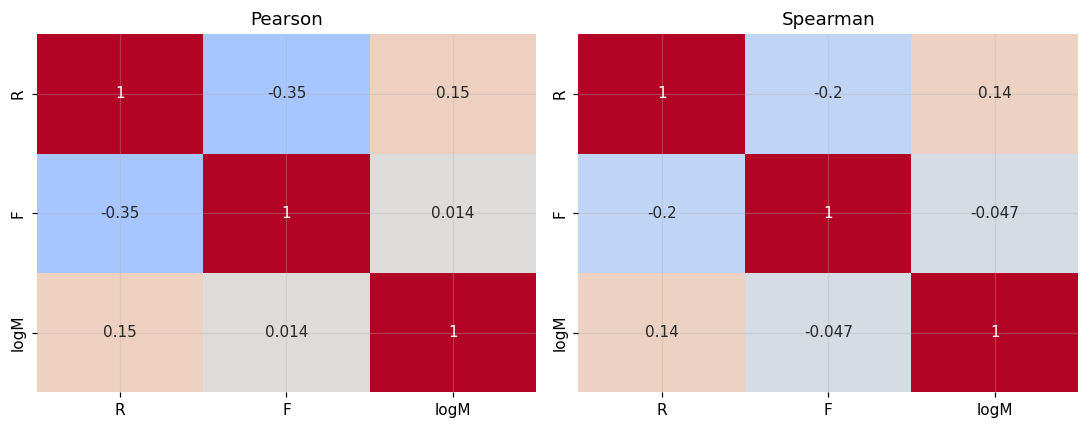

In [29]:
# Correlations among R, F, log1p(M)
cols = ["R", "F", "logM"]
corr_p = df[cols].corr(method="pearson").round(3)
corr_s = df[cols].corr(method="spearman").round(3)
print("Pearson:\n", corr_p, "\n\nSpearman:\n", corr_s)
corr_p.to_csv("outputs/rfm_correlation_pearson.csv")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (c, t) in zip(ax, [(corr_p, "Pearson"), (corr_s, "Spearman")]):
    sns.heatmap(c, annot=True, vmin=-1, vmax=1, cmap="coolwarm", ax=a, cbar=False); a.set_title(t)
plt.tight_layout(); plt.savefig("outputs/figures/2_5_correlations.png"); plt.show()

In [30]:
# Overlap in standardised space (eigenvalues)
# Overlap in standardised space: eigenvalues of the correlation matrix (equal = no overlap; one large = a shared dimension)
ev = np.sort(np.linalg.eigvalsh(df[cols].corr().values))[::-1]
print("Eigenvalues:", ev.round(3), "| share of total variance on first component:", (ev[0] / ev.sum()).round(3))

Eigenvalues: [1.375 1.01  0.615] | share of total variance on first component: 0.458


In [31]:
# Which features separate the clusters? (eta squared)
# Which features actually separate the clusters? (correlation alone does not prove dominance)
sel = pd.DataFrame({algo: {f: eta_sq(Z_act[:, i], labs["ACT"]) for i, f in enumerate(["R", "F", "log1p(M)"])}
                    for algo, labs in [("Ward", ward_labels), ("K-means", km_labels)]}).round(3)
print("\nShare of each feature's variance explained by the activity clusters (eta^2):\n", sel)


Share of each feature's variance explained by the activity clusters (eta^2):
            Ward  K-means
R         0.643    0.653
F         0.118    0.168
log1p(M)  0.516    0.540


### Task 2.5.2

In [32]:
# Repeat the selected Ward RFM solution on R and F only: same shares, same k, scaler refitted afresh
Z_rf = StandardScaler().fit_transform(df[["R", "F"]])
rf_labels = relabel(AgglomerativeClustering(n_clusters=K["ACT"], linkage="ward").fit_predict(Z_rf), df["M"])

full = ward_labels["ACT"]
print(f"Adjusted Rand index, full RFM Ward vs R,F-only Ward (k={K['ACT']}, {len(df)} shares):", round(adjusted_rand_score(full, rf_labels), 3))
print("Label-matched agreement:", round(matched_agreement(full, rf_labels), 3))
print("Silhouette full RFM:", round(silhouette_score(Z_act, full), 3), "| R,F only:", round(silhouette_score(Z_rf, rf_labels), 3),
      "(different feature spaces: not directly comparable)")
print(pd.crosstab(pd.Series(full + 1, name="Full RFM"), pd.Series(rf_labels + 1, name="R,F only")))

Adjusted Rand index, full RFM Ward vs R,F-only Ward (k=3, 485 shares): 0.291
Label-matched agreement: 0.66
Silhouette full RFM: 0.304 | R,F only: 0.489 (different feature spaces: not directly comparable)
R,F only    1   2   3
Full RFM             
1         182  66   1
2           3   0  79
3          86  59   9


In [33]:
# Traded value profiles with and without Monetary
# Traded value profiles (USD billions) in both solutions
cmp = pd.concat({
    "Full RFM":  df.groupby(full)["M_bn"].describe()[["count", "25%", "50%", "75%"]],
    "R,F only":  df.groupby(rf_labels)["M_bn"].describe()[["count", "25%", "50%", "75%"]]}, axis=1).round(2)
print("\nTraded value M (USD bn) by cluster:\n", cmp)
print("\nShare of log1p(M) variance explained by clusters (eta^2): full RFM =", round(eta_sq(df['logM'], full), 3),
      "| R,F only =", round(eta_sq(df['logM'], rf_labels), 3))
print("Profile of R,F-only clusters (original units):\n", profile(rf_labels, ("R", "F", "M_bn")))
cmp.to_csv("outputs/monetary_removal_traded_value.csv")


Traded value M (USD bn) by cluster:
   Full RFM                      R,F only                     
     count    25%    50%    75%    count    25%    50%    75%
0    249.0   7.87  11.15  14.93    271.0   9.41  14.93  30.53
1     82.0  13.02  17.85  32.50    125.0  10.52  17.70  31.80
2    154.0  28.22  39.70  68.39     89.0  13.74  20.85  33.25

Share of log1p(M) variance explained by clusters (eta^2): full RFM = 0.516 | R,F only = 0.004
Profile of R,F-only clusters (original units):
    n_shares  median_R_days  median_F  median_M_USDbn
0       271           11.0       4.0          14.926
1       125           11.0       2.0          17.699
2        89           54.0       2.0          20.848


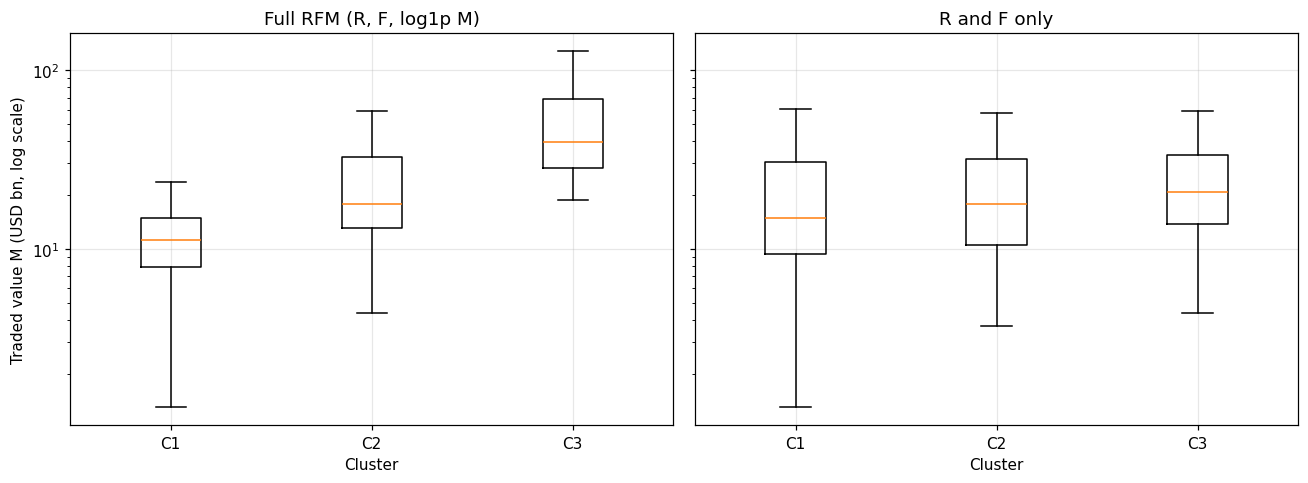

In [34]:
# Boxplot of traded value by cluster
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for a, (lab, t) in zip(ax, [(full, "Full RFM (R, F, log1p M)"), (rf_labels, "R and F only")]):
    a.boxplot([df.loc[lab == c, "M_bn"] for c in range(K["ACT"])], showfliers=False)
    a.set_xticks(range(1, K["ACT"] + 1)); a.set_xticklabels([f"C{c+1}" for c in range(K["ACT"])])   # portable across matplotlib versions
    a.set_yscale("log"); a.set_title(t); a.set_xlabel("Cluster")
ax[0].set_ylabel("Traded value M (USD bn, log scale)")
plt.tight_layout(); plt.savefig("outputs/figures/2_5_monetary_removal.png"); plt.show()

In [35]:
# Optional: does the treatment of skewed R matter? Compare with log1p(R) and with 1%/99% winsorised inputs (Ward, same k, same shares)
def ward_on(frame, k):
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(StandardScaler().fit_transform(frame))
base_act = ward_labels["ACT"]; base_rr = ward_labels["RR"]
alt_logR = ward_on(pd.DataFrame({"R": np.log1p(df["R"]), "F": df["F"], "logM": df["logM"]}), K["ACT"])
wins = lambda s: s.clip(s.quantile(.01), s.quantile(.99))
alt_win_act = ward_on(df[ACT_COLS].apply(wins), K["ACT"]); alt_win_rr = ward_on(df[RR_COLS].apply(wins), K["RR"])
print("ARI vs baseline | ACT with log1p(R):", round(adjusted_rand_score(base_act, alt_logR), 3),
      "| ACT winsorised:", round(adjusted_rand_score(base_act, alt_win_act), 3),
      "| RR winsorised:", round(adjusted_rand_score(base_rr, alt_win_rr), 3))

ARI vs baseline | ACT with log1p(R): 0.887 | ACT winsorised: 0.727 | RR winsorised: 0.781


In [36]:
# Feature table with one row per share and all cluster assignments (labels are 1-based, numbered by ascending median beta / M)
assign = df[["sector", "mean_weekly_return", "weekly_beta", "R", "F", "M", "logM"]].copy()
assign["ward_RR"]   = ward_labels["RR"]  + 1
assign["kmeans_RR"] = km_labels["RR"]    + 1
assign["ward_ACT"]  = ward_labels["ACT"] + 1
assign["kmeans_ACT"] = km_labels["ACT"]  + 1
assign["ward_RF_only"] = rf_labels + 1
assign.to_csv("outputs/cluster_assignments.csv")

In [37]:
# Save run metadata
run = {"seed": SEED, "n_init": N_INIT, "k_range": [2, 8], "chosen_k": K, "n_shares": int(len(df)),
       "ward": "scipy/sklearn Ward linkage, Euclidean, standardised features",
       "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scipy": scipy.__version__,
                    "scikit-learn": sklearn.__version__, "matplotlib": plt.matplotlib.__version__, "seaborn": sns.__version__}}
json.dump(run, open("outputs/task2_run_metadata.json", "w"), indent=2)
print(assign.head()); print(sorted(os.listdir("outputs")))

                        sector  mean_weekly_return  weekly_beta   R  F  \
Ticker                                                                   
MMM                Industrials            0.001142     0.869079  11  4   
AOS                Industrials            0.001991     1.042804  11  2   
ABT                Health Care            0.000971     0.583542  11  1   
ABBV               Health Care            0.003749     0.425366  11  3   
ACN     Information Technology            0.002376     1.143301  11  2   

                   M       logM  ward_RR  kmeans_RR  ward_ACT  kmeans_ACT  \
Ticker                                                                      
MMM     2.599146e+10  23.981034        3          3         3           1   
AOS     4.748980e+09  22.281196        3          3         1           1   
ABT     3.523027e+10  24.285172        1          1         3           3   
ABBV    6.837054e+10  24.948208        2          1         3           3   
ACN     5.199430e+1